# Dataset Overview (From Kaggle)

Centrifugal chillers are critical components in modern HVAC systems, consuming significant electrical energy in large commercial and industrial buildings. Early and accurate Fault Detection and Diagnosis (FDD) is essential for maintaining energy efficiency, preventing unexpected shutdowns, and reducing maintenance costs.

This dataset provides preprocessed telemetry sensor data optimized for developing, benchmarking, and evaluating machine learning and deep learning models for time-series classification and chiller fault diagnosis.

## Data Source (From Kaggle)

The dataset is derived from the benchmark ASHRAE Research Project 1043 (RP-1043), which contains experimental measurements collected under controlled conditions from a 90-ton water-cooled centrifugal chiller operating across various operating loads and fault severity levels.

## Data Collection & Physical Fault Injection (From Kaggle)

Unlike purely synthetic datasets generated via mathematical noise, this dataset originates from empirical experiments conducted on an actual industrial-grade **90-ton water-cooled centrifugal chiller testbed** under ASHRAE Research Project 1043.

The data generation adheres to rigorous physical measurement protocols:

- **Real Operational Testbed:** Run under dynamic, real-world cooling loads and condenser water conditions to capture genuine operational transients and system inertia.
- **Controlled Physical Fault Injection:** Faults were deliberately and physically introduced into the operating system rather than simulated via heuristic rules. For example:
  - _Refrigerant leaks and overcharges_ were realized by physically removing or adding controlled mass increments of refrigerant.
  - _Condenser fouling_ was simulated by physically restricting tube channels to emulate scale/deposit resistance.
  - _Non-condensables_ were induced by bleeding measured amounts of nitrogen/air into the circuit.
  - _Flow reductions and oil imbalances_ were directly actuated via throttling valves and precision oil injection/extraction.
- **Graded Fault Severity:** Each physical fault was evaluated across four progressive severity levels (SL1 to SL4) alongside varying thermal load ratios, capturing both subtle micro-deviations at early stages and acute system degradation.

## Fault Classes & Labels (From Kaggle)

The dataset covers normal operation along with several distinct typical chiller fault types, labeled by file name:

- **normal**: Normal baseline operation under standard operating conditions.
- **cf** _(Condenser Fouling)_: Accumulation of deposits or scaling on the condenser water tube surfaces, impairing heat transfer.
- **eo** _(Excess Oil)_: Overcharge of lubrication oil into the refrigerant circuit, degrading cooling performance.
- **fwc** _(Reduced Condenser Water Flow)_: Decreased water flow through the condenser due to valve or pump anomalies.
- **fwe** _(Reduced Evaporator Water Flow)_: Restricted chilled water flow across the evaporator.
- **nc** _(Non-condensable Gas)_: Presence of non-condensable gases (such as air) trapped inside the refrigerant circuit.
- **rl** _(Refrigerant Leak / Undercharge)_: Deficit in system refrigerant charge, reducing cooling capacity.
- **ro** _(Refrigerant Overcharge)_: Excess refrigerant charge, leading to elevated condenser pressure and compressor stress.

## Imports

In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

## Visualization aesthetic configuration

In [2]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

FAULT_ORDER = ['normal', 'cf', 'fwe', 'fwc', 'ro', 'rl', 'nc', 'eo']
FAULT_NAMES = {
    'normal': 'Normal Operation',
    'cf': 'Condenser Fouling (CF)',
    'fwe': 'Reduced Evaporator Flow (FWE)',
    'fwc': 'Reduced Condenser Flow (FWC)',
    'ro': 'Refrigerant Overcharge (RO)',
    'rl': 'Refrigerant Leakage (RL)',
    'nc': 'Non-condensable Gas (NC)',
    'eo': 'Excess Oil (EO)'
}

PALETTE = {
    'normal': '#2ecc71',  
    'cf':     '#e67e22',  
    'fwe':    '#3498db',  
    'fwc':    '#9b59b6',  
    'ro':     '#e74c3c',  
    'rl':     '#1abc9c', 
    'nc':     '#f39c12',  
    'eo':     '#34495e'   
}

# Resolve data directory

In [3]:
BASE_DIR = Path.cwd()
if (BASE_DIR / "data").exists():
    DATA_DIR = BASE_DIR / "data"
elif (BASE_DIR.parent / "data").exists():
    DATA_DIR = BASE_DIR.parent / "data"

print(f"Data directory: {DATA_DIR}")

Data directory: /home/henriquias/projects/eda-chiller-fault-detection-diagnostics-dataset/data


##  Read and Stratified Sample data from 8 parquet files

In [4]:
samples = []
N_PER_FAULT = 10000

for fault_name in FAULT_ORDER:
    fpath = DATA_DIR / f"{fault_name}.parquet"
    if not fpath.exists():
        print(f"Warning: File {fpath} not found!")
        continue
    
    t = pq.read_table(fpath)
    df_temp = t.to_pandas()
    
    if fault_name == 'normal':
        sampled = df_temp.sample(n=min(len(df_temp), N_PER_FAULT), random_state=42)
    else:
        n_per_sev = N_PER_FAULT // 4
        sampled = df_temp.groupby('severity_level', group_keys=False).apply(
            lambda g: g.sample(n=min(len(g), n_per_sev), random_state=42)
        )
    samples.append(sampled)
    print(f"✓ Loaded {fault_name:<8}: {len(sampled):,d} rows sampled from {len(df_temp):,d} total records.")

df = pd.concat(samples, ignore_index=True)
df['fault'] = pd.Categorical(df['fault'], categories=FAULT_ORDER, ordered=True)
print(f"\nTotal sampled DataFrame shape: {len(df):,d} rows, {df.shape[1]} columns.")

✓ Loaded normal  : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded cf      : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded fwe     : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded fwc     : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded ro      : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded rl      : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded nc      : 10,000 rows sampled from 2,000,000 total records.
✓ Loaded eo      : 10,000 rows sampled from 2,000,000 total records.

Total sampled DataFrame shape: 80,000 rows, 24 columns.


,source_file,time,fault,fault_id,severity_level,path_label,TEI,TEO,TCI,TCO,...,TR_dis,TCA,kW,TO_sump,PO_net,PRE,PRC,P_lift,CDW_DT,CHW_DT
0,synthetic_normal,18284010.0,normal,0,0.0,normal/0,49.32,44.42,85.36,89.06,...,121.96,1.60,92.59,131.77,27.37,44.21,105.74,61.53,3.70,4.90
1,synthetic_normal,12000710.0,normal,0,0.0,normal/0,53.16,44.42,76.21,82.46,...,115.20,2.74,135.89,124.86,27.44,44.19,95.82,51.62,6.25,8.74
2,synthetic_normal,1948490.0,normal,0,0.0,normal/0,50.53,44.42,86.68,91.20,...,123.95,1.97,118.39,133.90,27.07,44.12,110.43,66.31,4.52,6.11
3,synthetic_normal,16290540.0,normal,0,0.0,normal/0,51.35,44.42,86.73,91.86,...,125.59,2.28,137.56,135.59,27.32,44.06,112.30,68.25,5.13,6.93
4,synthetic_normal,1911440.0,normal,0,0.0,normal/0,51.59,44.42,76.71,81.77,...,114.40,2.28,113.65,124.78,27.27,44.10,93.93,49.83,5.06,7.17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,synthetic_eo,16466030.0,eo,7,NaN,eo/4,53.60,44.42,86.27,93.08,...,125.81,3.00,184.29,135.72,32.83,44.01,116.03,72.02,6.80,9.18
79996,synthetic_eo,17738740.0,eo,7,NaN,eo/4,52.77,44.42,83.19,89.24,...,121.40,2.69,154.97,131.35,32.58,44.04,108.40,64.35,6.05,8.35
79997,synthetic_eo,17793130.0,eo,7,NaN,eo/4,52.33,44.42,75.44,80.90,...,114.94,2.49,120.77,125.09,32.65,43.96,93.12,49.16,5.46,7.91
79998,synthetic_eo,17113970.0,eo,7,NaN,eo/4,55.35,44.42,75.71,83.51,...,115.93,3.43,176.41,125.80,32.66,44.05,98.24,54.19,7.79,10.93


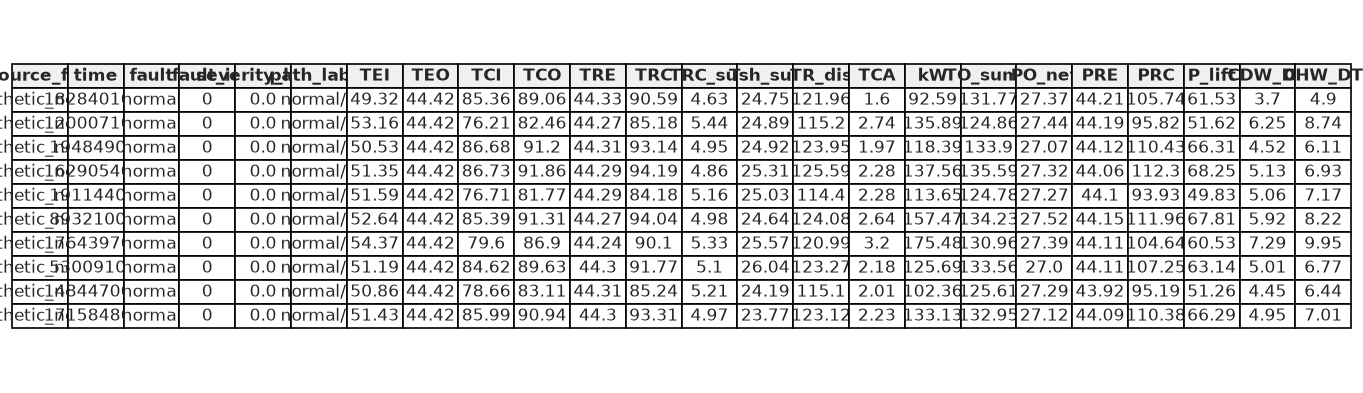

In [5]:
df_subset = df.head(10)

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('tight')
ax.axis('off')

tabela = ax.table(
    cellText=df_subset.values,
    colLabels=df_subset.columns,
    cellLoc='center',
    loc='center'
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(10)
tabela.scale(1.2, 1.2)

for (row, col), cell in tabela.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#f0f0f0')

plt.savefig('dataframe.png', bbox_inches='tight', dpi=900)

df

## Descriptive Statistics

Data types and missing value check:
Total null count: 0


/tmp/ipykernel_1243/4066273815.py:13: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_stats.reset_index(inplace=True)
/tmp/ipykernel_1243/4066273815.py:14: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_stats.rename(columns={'index': 'Feature'}, inplace=True)


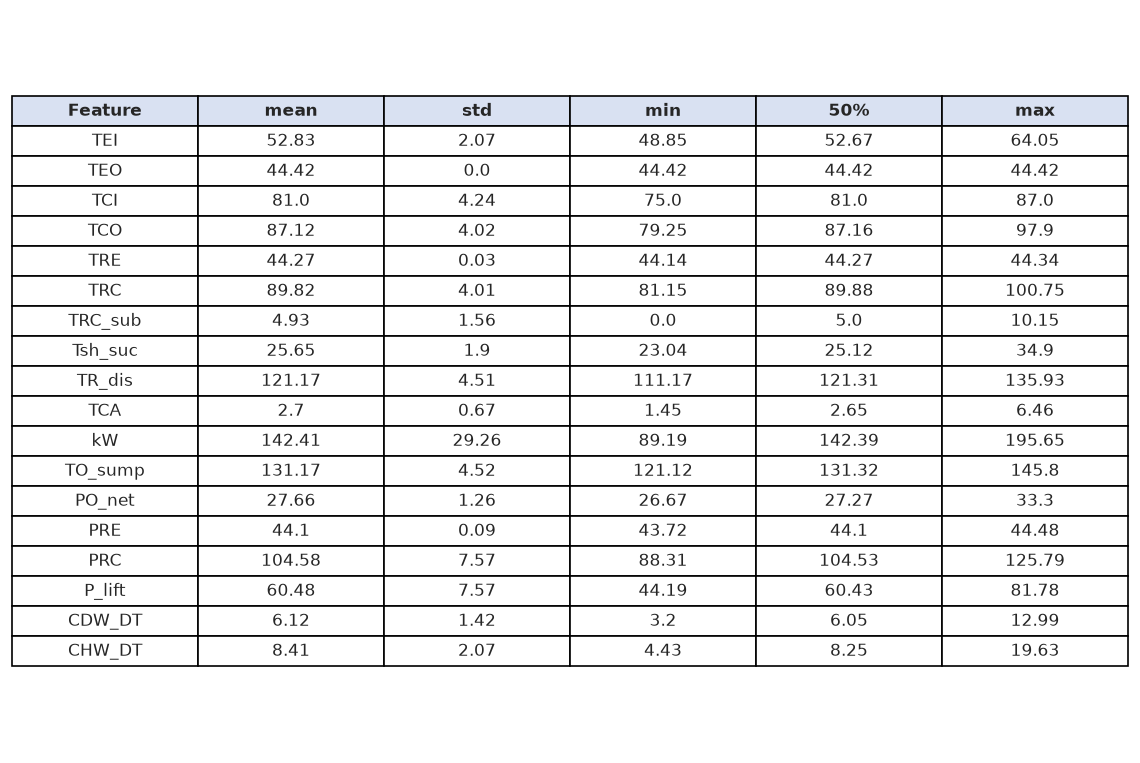

In [6]:
FEATURE_COLS = [
    'TEI', 'TEO', 'TCI', 'TCO', 'TRE', 'TRC', 'TRC_sub', 'Tsh_suc', 
    'TR_dis', 'TCA', 'kW', 'TO_sump', 'PO_net', 'PRE', 'PRC', 'P_lift', 
    'CDW_DT', 'CHW_DT'
]

print("Data types and missing value check:")
null_counts = df[FEATURE_COLS].isnull().sum()
print(f"Total null count: {null_counts.sum()}")

df_stats = df[FEATURE_COLS].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

df_stats.reset_index(inplace=True)
df_stats.rename(columns={'index': 'Feature'}, inplace=True)

fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('tight')
ax.axis('off')

tabela = ax.table(
    cellText=df_stats.values,
    colLabels=df_stats.columns,
    cellLoc='center',
    loc='center'
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(10)
tabela.scale(1.2, 1.5) 

for (row, col), cell in tabela.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#d9e1f2') 

plt.savefig('descriptive.png', bbox_inches='tight', dpi=300)

## 📊Sample Count by Class

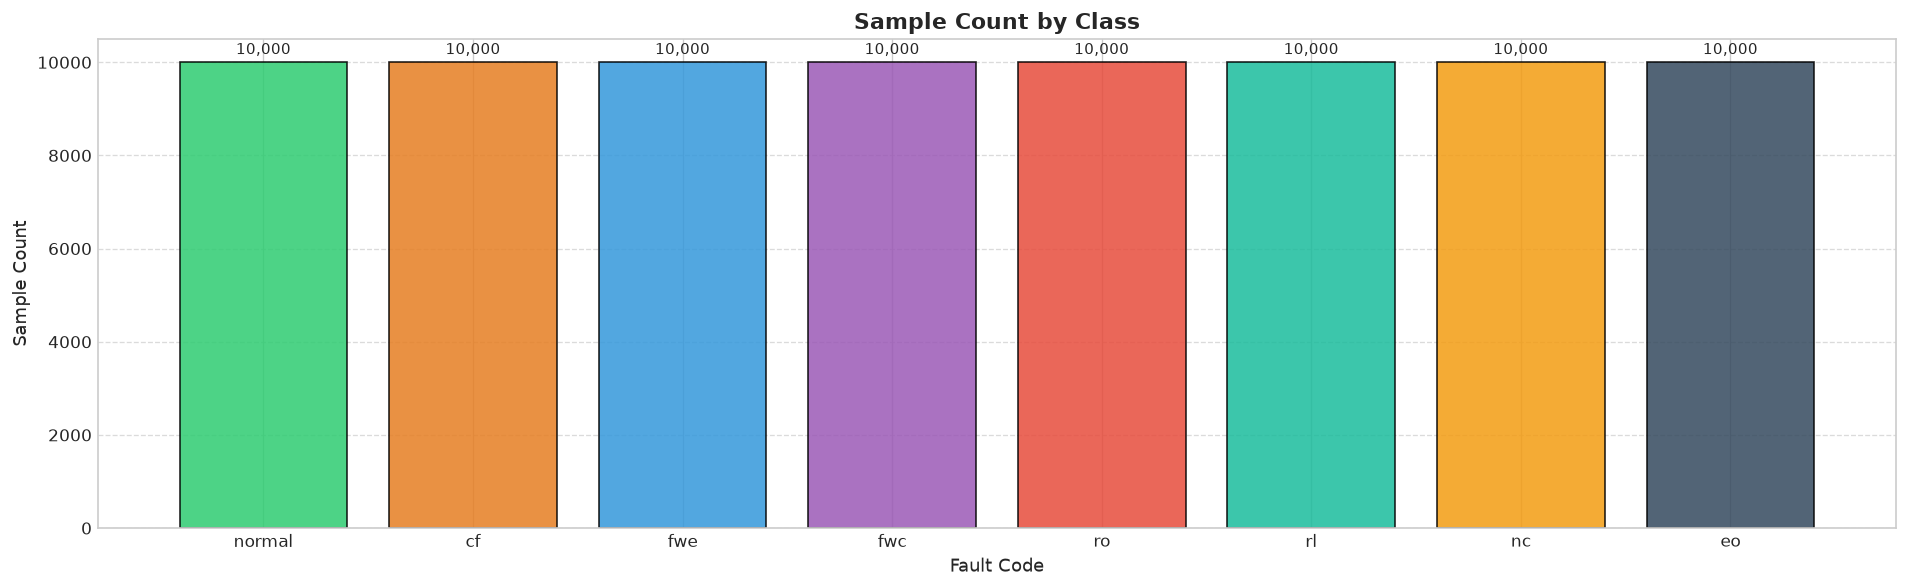

In [7]:

fig, ax = plt.subplots(figsize=(16, 5))

fault_counts = df['fault'].value_counts()[FAULT_ORDER]
bar_colors = [PALETTE[f] for f in FAULT_ORDER]

bars = ax.bar(
    fault_counts.index,
    fault_counts.values,
    color=bar_colors,
    edgecolor='black',
    alpha=0.85
)

ax.set_title('Sample Count by Class', fontweight='bold')
ax.set_xlabel('Fault Code')
ax.set_ylabel('Sample Count')
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 100,
        f'{int(yval):,}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.savefig('sample_count_by_class.png')
plt.show()


## 📊Sensor Distribution Matrix Across All 8 Classes

Key sensor variables evaluated:

- `kW`: Compressor electrical power consumption.
- `P_lift`: Pressure lift (*PRC - PRE*).
- `TCA`: Condenser Approach Temperature (*TRC - TCO*)
- `TRC_sub`: Condenser Subcooling temperature.
- `Tsh_suc`: Suction Superheat temperature.
- `PO_net`: Net lubricating oil pressure.

/tmp/ipykernel_1243/2749680054.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1243/2749680054.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1243/2749680054.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1243/2749680054.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1243/2749680054.py:15: FutureWarning: 

P

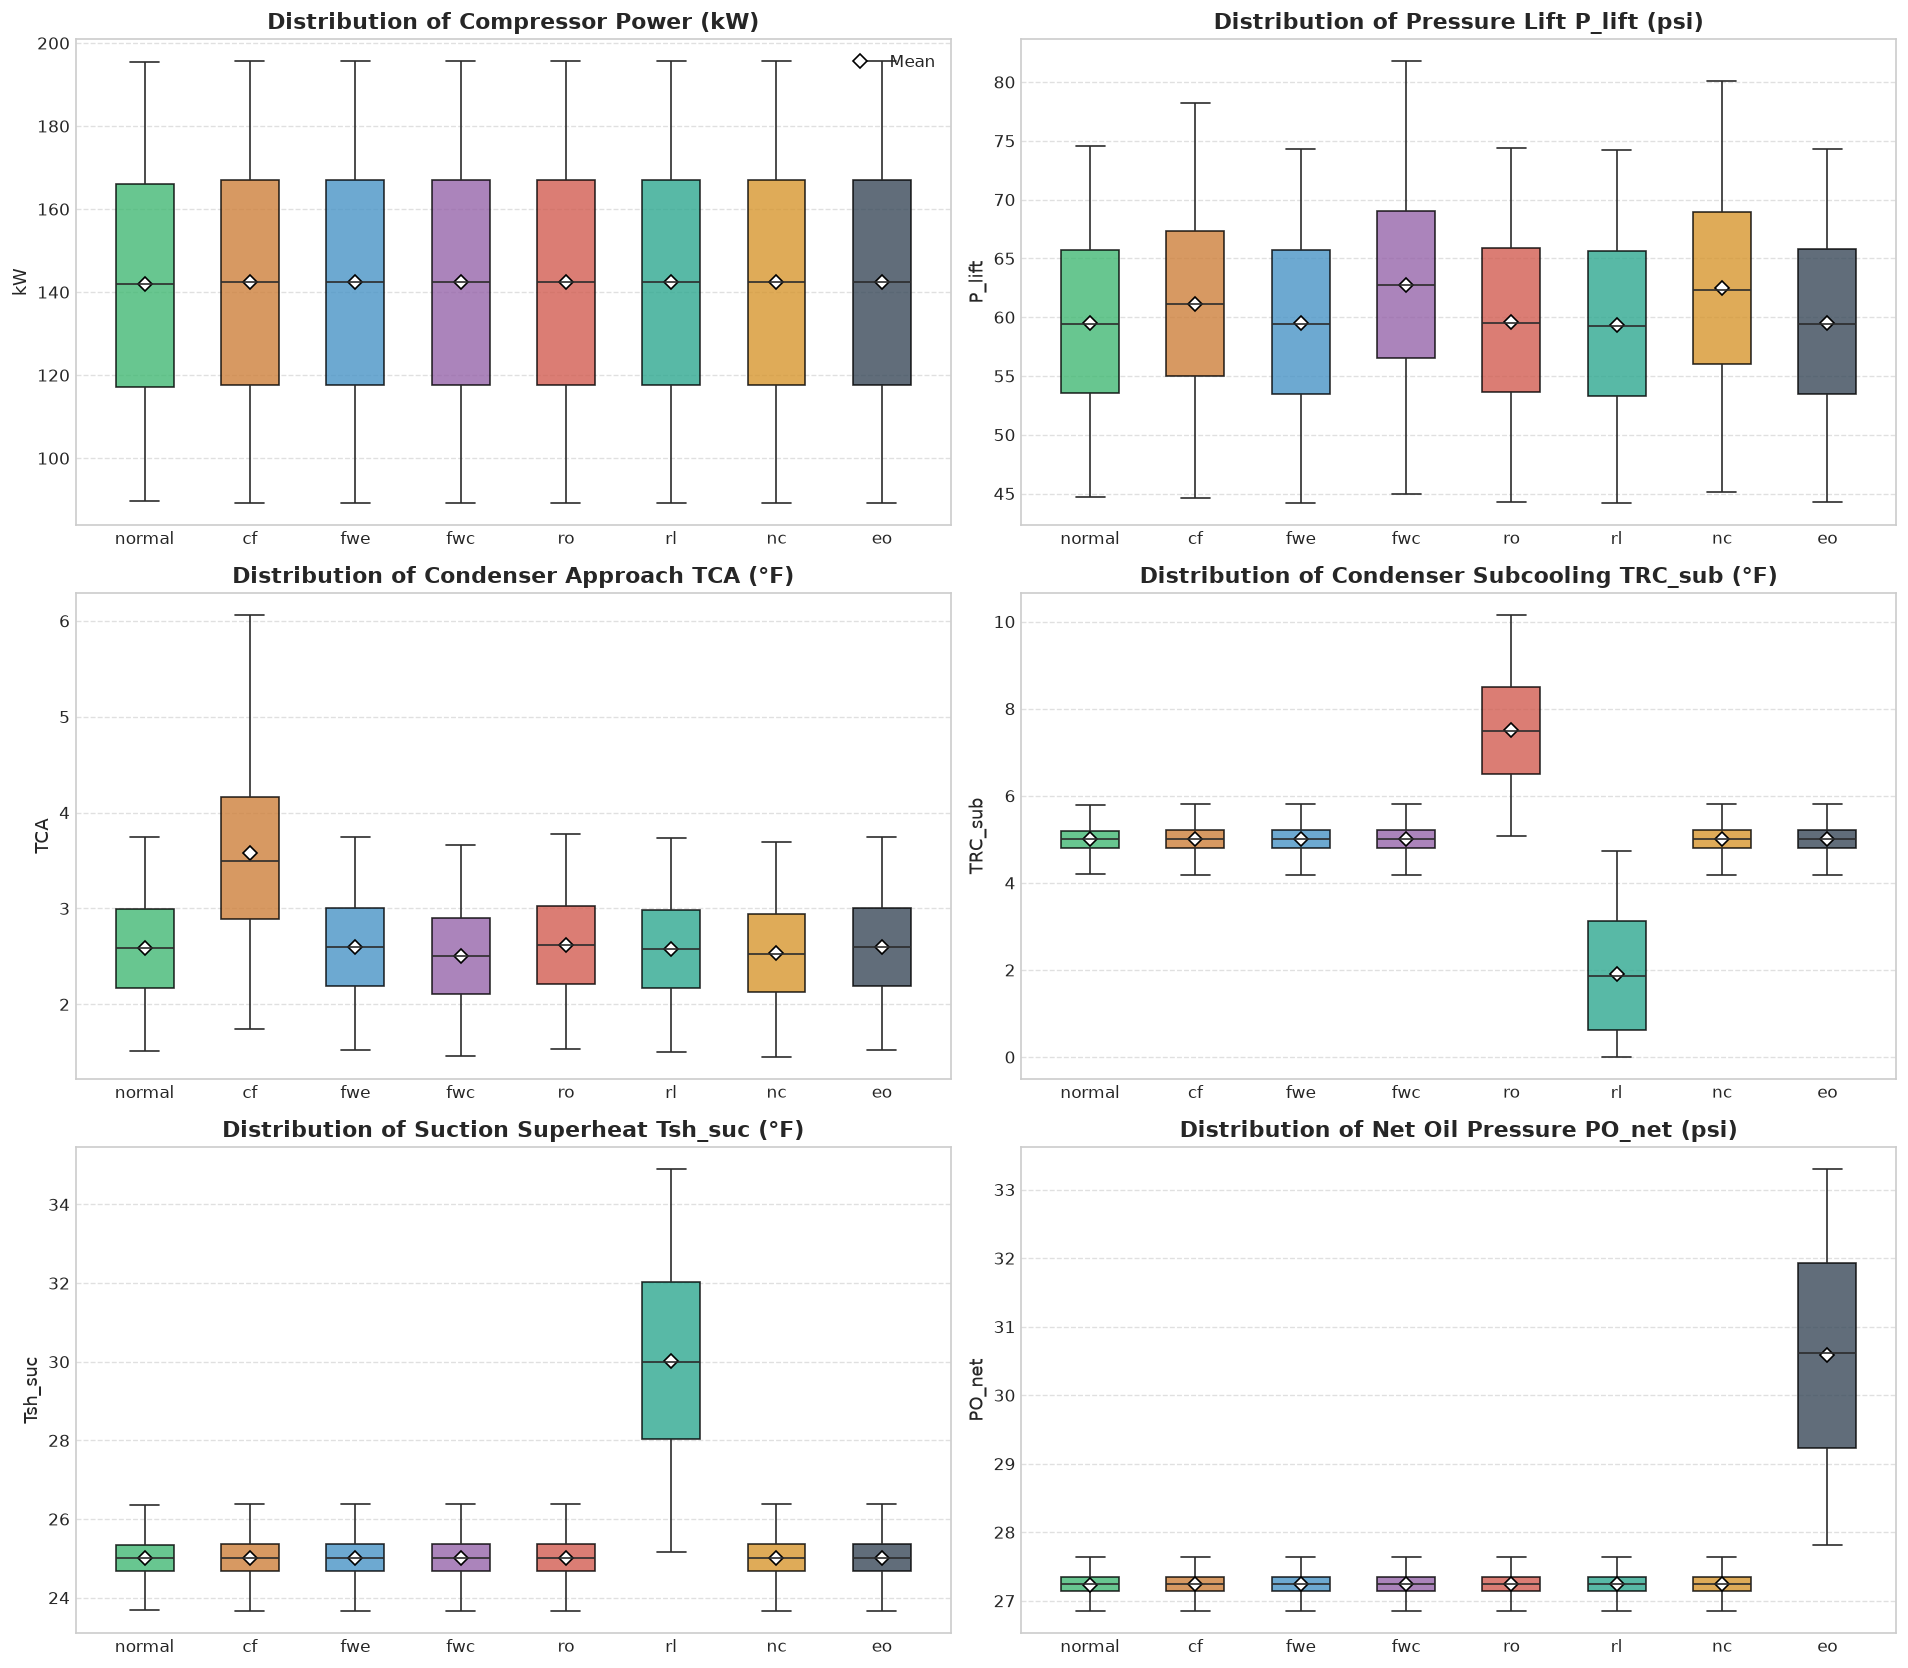

In [8]:
key_features = [
    ('kW', 'Compressor Power (kW)'),
    ('P_lift', 'Pressure Lift P_lift (psi)'),
    ('TCA', 'Condenser Approach TCA (°F)'),
    ('TRC_sub', 'Condenser Subcooling TRC_sub (°F)'),
    ('Tsh_suc', 'Suction Superheat Tsh_suc (°F)'),
    ('PO_net', 'Net Oil Pressure PO_net (psi)')
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, (col, title) in enumerate(key_features):
    ax = axes[idx]
    sns.boxplot(
        data=df, 
        x='fault', 
        y=col, 
        order=FAULT_ORDER, 
        palette=PALETTE,
        ax=ax, 
        showfliers=False,
        width=0.55,
        boxprops=dict(alpha=0.8, edgecolor='black')
    )
    # Add mean marker points
    means = df.groupby('fault', observed=True)[col].mean()[FAULT_ORDER]
    ax.plot(range(len(FAULT_ORDER)), means, 'D', color='white', markeredgecolor='black', markersize=6, label='Mean' if idx == 0 else "")
    
    ax.set_title(f'Distribution of {title}', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(col)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    if idx == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('key_features_boxplots.png')
plt.show()